### Example of using gym - I have used the mountain car environment to illustrate ###

- We start with an environment called MountainCar, where the objective is to drive a car up a mountain. The car is on a one-dimensional track, positioned between two "mountains". The goal is to drive up the mountain on the right; however, the car's engine is not strong enough to scale the mountain in a single go. Therefore, the only way to succeed is to drive back and forth to build up momentum.

- The observation for the mountain car environment is a vector of two numbers representing velocity and position. The middle point between the two mountains is taken to be the origin, with right being the positive direction and left being the negative direction.

- We see that both the observation space as well as the action space are represented by classes called Box and Discrete, respectively. These are one of the various data structures provided by gym in order to implement observation and action spaces for different kind of scenarios (discrete action space, continuous action space, etc)

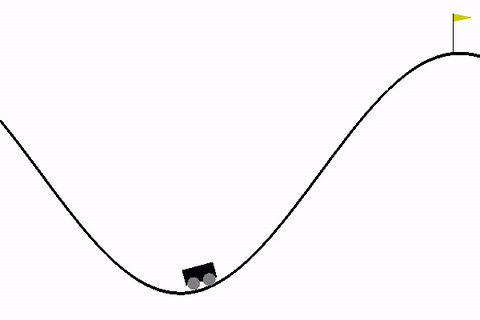

In [1]:
import random
from collections import deque

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

In [7]:
# Hyperparameters

ENV_ID = "MountainCar-v0"
GAMMA = 0.99
LR = 1e-3
BATCH_SIZE = 64
BUFFER_CAPACITY = 50_000
MIN_BUFFER_SIZE = 1_000
TARGET_UPDATE_FREQ = 10  # episodes
MAX_EPISODES = 2000

# Epsilon-greedy schedule
EPSILON_START = 1.0
EPSILON_END = 0.02
EPSILON_DECAY = 0.992

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(DEVICE)

mps


In [8]:
# Q-Network

class QNetwork(nn.Module):
    def __init__(self, state_dim: int, action_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

In [9]:
# Replay Buffer

class ReplayBuffer:
    def __init__(self, capacity: int):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        states, actions, rewards, next_states, dones = zip(
            *random.sample(self.buffer, batch_size)
        )
        return (
            torch.tensor(np.array(states), dtype=torch.float32, device=DEVICE),
            torch.tensor(actions, dtype=torch.long, device=DEVICE).unsqueeze(1),
            torch.tensor(rewards, dtype=torch.float32, device=DEVICE).unsqueeze(1),
            torch.tensor(np.array(next_states), dtype=torch.float32, device=DEVICE),
            torch.tensor(dones, dtype=torch.float32, device=DEVICE).unsqueeze(1),
        )

    def __len__(self):
        return len(self.buffer)

In [10]:
# Training Loop

def train():
    env = gym.make(ENV_ID)
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    q_net = QNetwork(state_dim, action_dim).to(DEVICE)
    target_net = QNetwork(state_dim, action_dim).to(DEVICE)
    target_net.load_state_dict(q_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(q_net.parameters(), lr=LR)
    loss_fn = nn.SmoothL1Loss()  # Huber loss for stability
    replay_buffer = ReplayBuffer(BUFFER_CAPACITY)

    epsilon = EPSILON_START
    recent_scores = deque(maxlen=20)

    for episode in range(1, MAX_EPISODES + 1):
        state, _ = env.reset()
        episode_reward = 0
        done = False

        while not done:
            # Epsilon-greedy action selection
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    state_t = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                    action = q_net(state_t).argmax(dim=1).item()

            next_state, env_reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # --- Reward Shaping ---
            # Default MountainCar gives -1 everywhere.
            # Reward building mechanical energy (height + speed):
            shaped_reward = env_reward + 10.0 * (abs(next_state[1]) + (next_state[0] + 0.5) ** 2)
            if terminated and next_state[0] >= 0.5:
                shaped_reward += 50.0  # Big bonus for reaching the flag

            replay_buffer.push(state, action, shaped_reward, next_state, terminated)
            state = next_state
            episode_reward += env_reward  # Track original gym score

            # Optimization step
            if len(replay_buffer) >= MIN_BUFFER_SIZE:
                b_states, b_actions, b_rewards, b_next_states, b_dones = replay_buffer.sample(BATCH_SIZE)

                # Current Q(s, a)
                curr_q = q_net(b_states).gather(1, b_actions)

                # Target Q: r + gamma * max_a' Q_target(s', a') * (1 - done)
                with torch.no_grad():
                    max_next_q = target_net(b_next_states).max(dim=1, keepdim=True)[0]
                    target_q = b_rewards + (GAMMA * max_next_q * (1.0 - b_dones))

                loss = loss_fn(curr_q, target_q)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        # Decay epsilon
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

        # Sync target network periodically
        if episode % TARGET_UPDATE_FREQ == 0:
            target_net.load_state_dict(q_net.state_dict())

        recent_scores.append(episode_reward)
        avg_score = np.mean(recent_scores)

        if episode % 20 == 0:
            print(f"Episode {episode:3d} | Epsilon: {epsilon:.3f} | Last Score: {episode_reward:5.0f} | Avg(20): {avg_score:5.1f}")

        # MountainCar-v0 is considered solved when average score is >= -110 over consecutive episodes
        if len(recent_scores) == 20 and avg_score >= -110.0:
            print(f"\n Solved in {episode} episodes! Average Score: {avg_score:.1f}")
            torch.save(q_net.state_dict(), "mountaincar_dqn.pth")
            break

    env.close()
    return q_net




In [11]:
# Evaluation / Rendering

def evaluate(q_net, episodes=3):
    test_env = gym.make(ENV_ID, render_mode="human")
    for ep in range(episodes):
        state, _ = test_env.reset()
        total_reward = 0
        done = False
        while not done:
            with torch.no_grad():
                state_t = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                action = q_net(state_t).argmax(dim=1).item()
            state, reward, terminated, truncated, _ = test_env.step(action)
            total_reward += reward
            done = terminated or truncated
        print(f"Test Episode {ep + 1}: Score = {total_reward}")
    test_env.close()


In [12]:
# Run training

trained_model = train()

Episode  20 | Epsilon: 0.852 | Last Score:  -200 | Avg(20): -200.0
Episode  40 | Epsilon: 0.725 | Last Score:  -200 | Avg(20): -200.0
Episode  60 | Epsilon: 0.618 | Last Score:  -200 | Avg(20): -200.0
Episode  80 | Epsilon: 0.526 | Last Score:  -200 | Avg(20): -200.0
Episode 100 | Epsilon: 0.448 | Last Score:  -200 | Avg(20): -198.6
Episode 120 | Epsilon: 0.381 | Last Score:  -181 | Avg(20): -198.6
Episode 140 | Epsilon: 0.325 | Last Score:  -200 | Avg(20): -193.3
Episode 160 | Epsilon: 0.277 | Last Score:  -200 | Avg(20): -186.7
Episode 180 | Epsilon: 0.236 | Last Score:  -162 | Avg(20): -176.1
Episode 200 | Epsilon: 0.201 | Last Score:  -178 | Avg(20): -174.7
Episode 220 | Epsilon: 0.171 | Last Score:  -174 | Avg(20): -172.8
Episode 240 | Epsilon: 0.145 | Last Score:  -118 | Avg(20): -169.5
Episode 260 | Epsilon: 0.124 | Last Score:  -158 | Avg(20): -161.9
Episode 280 | Epsilon: 0.106 | Last Score:  -102 | Avg(20): -158.6
Episode 300 | Epsilon: 0.090 | Last Score:  -163 | Avg(20): -1

In [13]:
# Evaluation

evaluate(trained_model)

Test Episode 1: Score = -161.0
Test Episode 2: Score = -144.0
Test Episode 3: Score = -142.0
